# PPO Baselines: `intersection-v0` and `merge-v0`
Environment inspection, reference policies, PPO training with live demos, evaluation, and episode replays.

In [11]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image

from conformal_nav.config import load_config
from conformal_nav.envs import make_env
from conformal_nav.evaluation import evaluate
from conformal_nav.training import train_ppo
from conformal_nav.viz import record_episode, save_gif

# intersection-v0 warns that v1 exists; harmless since we set every config key explicitly.
warnings.filterwarnings("ignore", message=".*out of date.*")

SEED = 42
TIMESTEPS = 5_000      # raise to 20_000+ for a stronger policy (~61 steps/s on an M-series CPU)
EVAL_EPISODES = 20
WATCH_EVERY = 1_000    # live pygame demo every N training steps; None = train headless (faster)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Inspect the intersection environment
What the agent sees (observation), what it can do (actions), and one rendered frame.

observation shape: (15, 7)
actions: {0: 'SLOWER', 1: 'IDLE', 2: 'FASTER'}


,presence,x,y,vx,vy,cos_h,sin_h
0,1.0,0.020,0.466,0.000,-0.5,0.0,-1.0
1,1.0,-0.212,0.020,0.379,0.0,1.0,-0.0
2,1.0,-0.461,0.020,0.400,0.0,1.0,-0.0
3,1.0,0.807,-0.020,-0.311,0.0,-1.0,0.0
4,1.0,0.521,-0.020,-0.439,0.0,-1.0,0.0
5,0.0,0.000,0.000,0.000,0.0,0.0,0.0


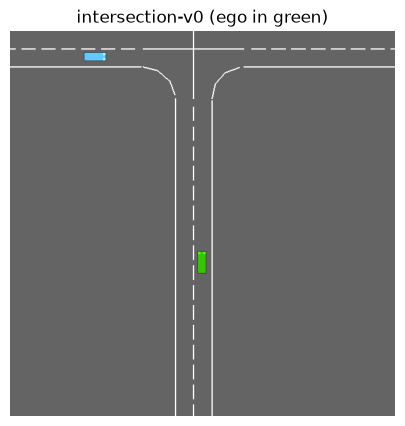

In [2]:
cfg_int = load_config("intersection")
env = make_env(cfg_int, render_mode="rgb_array")
obs, info = env.reset(seed=SEED)

print("observation shape:", obs.shape)
print("actions:", env.unwrapped.action_type.actions)

# Row 0 = ego, rows 1.. = nearest vehicles; presence=0 rows are padding.
features = cfg_int["env_config"]["observation"]["features"]
display(pd.DataFrame(obs, columns=features).round(3).head(6))

plt.figure(figsize=(5, 5))
plt.imshow(env.render())
plt.axis("off")
plt.title("intersection-v0 (ego in green)")
plt.show()

## 2. Reference policies (no learning)
Constant policies bound the trade-off: always `FASTER` is aggressive, always `SLOWER` freezes.
All evaluations use the same seeds, so every policy faces identical traffic.

In [3]:
eval_env = make_env(cfg_int)
eval_seed = SEED + cfg_int["eval"]["seed_offset"]  # disjoint from training seeds

results = {
    "always SLOWER": evaluate(lambda o: 0, eval_env, "intersection", EVAL_EPISODES, eval_seed),
    "always FASTER": evaluate(lambda o: 2, eval_env, "intersection", EVAL_EPISODES, eval_seed),
}
pd.DataFrame(results).T.round(3)

,episodes,collision_rate,completion_rate,timeout_rate,avg_speed,avg_length,avg_return
always SLOWER,20.0,0.0,0.0,1.0,0.505,13.0,0.000
always FASTER,20.0,0.3,0.7,0.0,8.839,8.0,6.221


## 3. Train and evaluate PPO on `intersection-v0`
A pygame window pops up every `WATCH_EVERY` steps and drives one real-time episode with the *current* policy,
always on the same traffic seed, so you can watch the behaviour change as PPO learns.

In [13]:
ppo_int = train_ppo(cfg_int, total_timesteps=TIMESTEPS, seed=SEED, verbose=0, watch_every=WATCH_EVERY)

results["PPO"] = evaluate(
    lambda o: int(ppo_int.predict(o, deterministic=True)[0]),
    eval_env, "intersection", EVAL_EPISODES, eval_seed,
)
pd.DataFrame(results).T.round(3)

[live demo @      4 steps] CRASH
[live demo @   1004 steps] CRASH
[live demo @   2004 steps] CRASH
[live demo @   3004 steps] CRASH
[live demo @   4004 steps] CRASH
[live demo @   5004 steps] CRASH
[live demo @   5120 steps] CRASH
Trained 5000 steps in 116s


,episodes,collision_rate,completion_rate,timeout_rate,avg_speed,avg_length,avg_return
always SLOWER,20.0,0.0,0.0,1.0,0.505,13.0,0.000
always FASTER,20.0,0.3,0.7,0.0,8.839,8.0,6.221
PPO,20.0,0.3,0.7,0.0,8.839,8.0,6.221


## 4. Same pipeline on `merge-v0`

In [ ]:
cfg_merge = load_config("merge")
merge_env = make_env(cfg_merge)
merge_seed = SEED + cfg_merge["eval"]["seed_offset"]

ppo_merge = train_ppo(cfg_merge, total_timesteps=TIMESTEPS, seed=SEED, verbose=0, watch_every=WATCH_EVERY)

merge_results = {
    "always IDLE": evaluate(lambda o: 1, merge_env, "merge", EVAL_EPISODES, merge_seed),
    "PPO": evaluate(
        lambda o: int(ppo_merge.predict(o, deterministic=True)[0]),
        merge_env, "merge", EVAL_EPISODES, merge_seed,
    ),
}
pd.DataFrame(merge_results).T.round(3)

Trained 5000 steps in 31s


,episodes,collision_rate,completion_rate,timeout_rate,avg_speed,avg_length,avg_return
always IDLE,20.0,1.0,0.0,0.0,27.936,5.9,5.207
PPO,20.0,0.2,0.8,0.0,20.343,16.8,14.559


## 5. Watch the trained agents
Replays capture every 15 Hz physics frame (the agent decides at 1 Hz). Ego is green; GIFs are saved under `runs/replays/`.

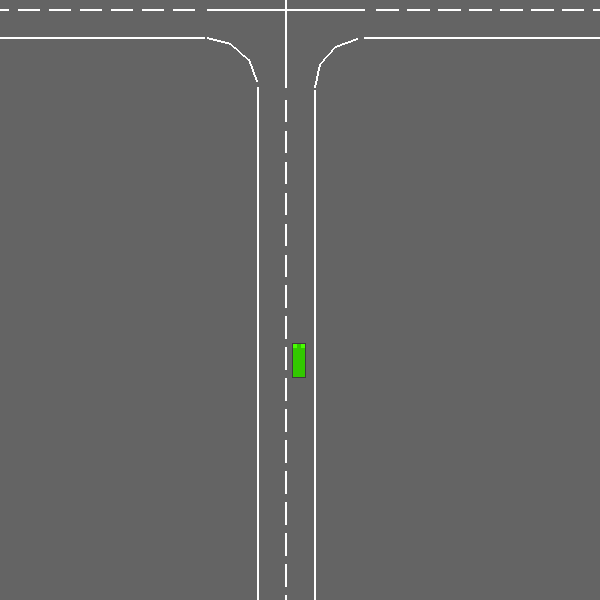

In [8]:
REPLAY_SEED = eval_seed  # try eval_seed + k to see other traffic scenarios

frames = record_episode(
    lambda o: int(ppo_int.predict(o, deterministic=True)[0]),
    make_env(cfg_int, render_mode="rgb_array"),
    seed=REPLAY_SEED,
)
gif = save_gif(frames, "../runs/replays/intersection_ppo.gif")
Image(filename=gif)

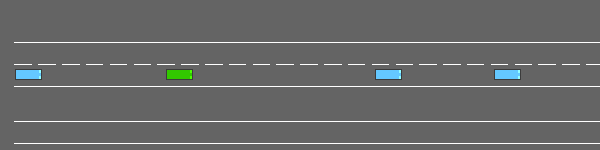

In [9]:
frames = record_episode(
    lambda o: int(ppo_merge.predict(o, deterministic=True)[0]),
    make_env(cfg_merge, render_mode="rgb_array"),
    seed=merge_seed,
)
gif = save_gif(frames, "../runs/replays/merge_ppo.gif")
Image(filename=gif)